# Execution Algorithm Research — SET50 (hourly)

**คำถามวิจัย:** ถ้าใช้ *parent order ชุดเดียวกัน* algo แต่ละตัวเสียต้นทุน execution ต่างกันเท่าไหร่ และผลนี้ขึ้นกับขนาด order, ช่วงเวลาของวัน, volatility และปีแค่ไหน

algo ที่เทียบ: **MARKET, TWAP, VWAP, POV10, POV5, POV5/10** (POV5/10 = 5% ช่วงเช้า / 10% ช่วงบ่าย)

**สมมติฐานที่ทดสอบ**
1. **H1** order ยิ่งใหญ่เมื่อเทียบกับ ADV algo ที่ทยอยส่งจะยิ่งถูกกว่า MARKET เพราะ impact เพิ่มตาม √ขนาด
2. **H2** VWAP ถูกกว่า TWAP เพราะส่งหนักในชั่วโมงที่ตลาดซื้อขายมาก
3. **H3** algo ที่ทยอยส่งแลกต้นทุนที่ต่ำลงด้วยความเสี่ยงที่สูงขึ้น (std ของ IS)
4. **H4** POV ที่ rate ต่ำกว่าเสีย impact น้อยกว่า แต่เสี่ยงทำไม่เสร็จ และการแบ่ง rate ตามช่วงเช้า/บ่ายช่วยลดต้นทุนได้

ทุกค่าที่ปรับได้อยู่ใน `src/constants.py` การทดลองทั้งหมดรันผ่าน `src/experiment.run_experiment()` ตัวเดียวกับ `run.py`

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from src import constants as C, plots
from src.experiment import run_experiment

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plots.style()
ex = run_experiment()                      # ~15 s: main run + sensitivity
mk, summ = ex["market"], ex["summary"]

## 1. ข้อมูลและการเตรียมข้อมูล

* ไฟล์ `SET50_2023–2026.csv` แท่งรายชั่วโมง มี OHLC, `TRADING_VALUE` (บาท) และ `TRADING_VOLUME` (หุ้น)
* **Universe lock 10 ตัวตลอดช่วง:** KBANK, CPALL, ADVANC, PTTEP, AOT, BBL, SCB, PTT, KTB, BDMS ทุกตัวสภาพคล่องสูง ข้อมูลครบตั้งแต่ ม.ค. 2023 และไม่มีราคากระโดดจาก corporate action ที่ยังไม่ได้ปรับ
* เก็บแท่ง **10, 11, 12, 13, 15, 16, 17** ได้ 7 แท่งต่อวัน ตัดแท่ง 14:00 กับแถวแปลกๆ นอกเวลาทิ้ง
* **Bar VWAP** = value ÷ volume clip ให้อยู่ในช่วง [low, high] ใช้เป็นราคา fill
* **VWAP profile แบบ rolling:** ณ วัน d ใช้สัดส่วนมูลค่าซื้อขายรายชั่วโมง เฉลี่ยรวมทั้ง 10 ตัว ของ **21 วันเทรดก่อนหน้า** (ไม่นับวัน d จึงไม่มี look-ahead) backtest จึงเริ่มได้ตั้งแต่ ก.พ. 2023 ยาวราว **3.8 ปี**
* **ADV** = มูลค่าซื้อขายเฉลี่ยต่อวันของ 20 วันก่อนหน้า ใช้รายงานว่า order ใหญ่แค่ไหนเมื่อเทียบกับตลาด

,data
files,"[SET50_2023.csv, SET50_2024.csv, SET50_2025.cs..."
rows_raw,343633
rows_off_grid,6370
bars,6576
tickers,"[KBANK, CPALL, ADVANC, PTTEP, AOT, BBL, SCB, P..."
start,2023-01-03 10:00:00
end,2026-11-19 17:00:00
jump_bars,0
vwap_clipped_share,0.00
first_profile_day,2023-02-01


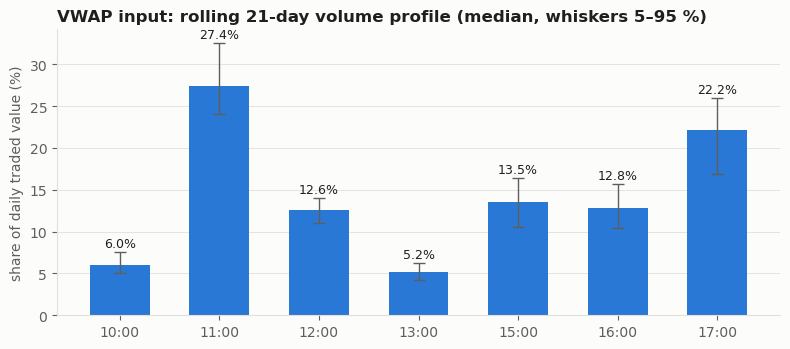

hour,10,11,12,13,15,16,17
5%,5.00,24.01,11.05,4.27,10.53,10.38,16.89
50%,6.04,27.37,12.58,5.18,13.54,12.82,22.17
95%,7.51,32.54,13.97,6.25,16.44,15.71,25.90


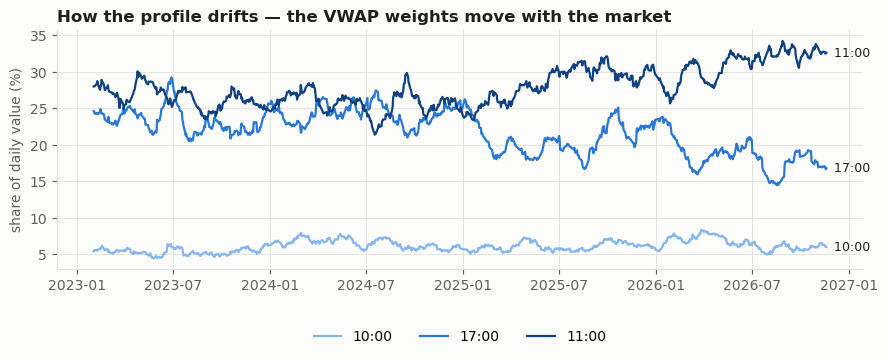

In [2]:
display(pd.Series(mk.info, name="data").to_frame())
plots.volume_profile(mk.profile); plt.show()
display((mk.profile.dropna().describe(percentiles=[.05, .5, .95]).loc[["5%", "50%", "95%"]] * 100))
plots.profile_over_time(mk.profile); plt.show()

## 2. Market model และ cost model

ทุก child order fill ที่ **VWAP ของแท่งที่ fill** และจ่ายต้นทุนดังนี้

| ส่วน | สูตร | หมายเหตุ |
|---|---|---|
| ½ spread | `SPREAD_TICKS × tick(price) / 2` | **ค่าสมมติ** 1 tick เพราะไม่มี bid/ask (sensitivity ที่ 2 tick) |
| impact | `Y × σ_hour × √(child ÷ มูลค่าซื้อขายของแท่ง) × price` | square-root law, Y = 1 (sensitivity 0.5, 2), σ ex-ante 100 แท่ง |
| commission | 0.157% × (1 + VAT 7%) | |

กติกาการ fill
* ตัดสินใจและตั้ง arrival ที่ Close_t แล้ว child แรกเริ่มที่แท่ง t+1
* แท่งที่ไม่มีการซื้อขาย fill ไม่ได้
* impact เป็นแบบชั่วคราว ไม่สะสมข้ามแท่ง

## 3. ออกแบบการทดลอง — parent order

1. สุ่ม **2,000 ชุด** ของ (แท่งที่ตัดสินใจ, หุ้น, ฝั่งซื้อ/ขาย) ตลอดช่วง **ก.พ. 2023 → พ.ย. 2026** สุ่มหุ้นจาก 10 ตัวที่ lock ไว้
2. แต่ละชุดใช้ **ทั้ง 4 ขนาด** คือ 1%, 5%, 10% และ 25% ของ NAV 100M ได้ทั้งหมด **8,000 order** ผลของขนาดจึงวัดบนเวลา หุ้น และฝั่งเดียวกันทุกประการ
3. **ทุก algo execute order ชุดเดียวกัน** การเทียบจึงเป็นแบบ paired
4. ฝั่งขายถือว่ามีหุ้นอยู่แล้ว ไม่มีข้อจำกัดเรื่องพอร์ตหรือเงินสด

In [3]:
od = ex["orders"]
print(ex["orders_info"])
display(od.groupby("bucket", sort=False).agg(n=("order_id", "size"), notional_M=("paper_notional", lambda s: s.mean() / 1e6),
        pct_adv_median=("pct_adv", lambda s: s.median() * 100), pct_adv_p95=("pct_adv", lambda s: s.quantile(.95) * 100))
        .sort_values("notional_M"))
base = od.drop_duplicates("base_id")
display(pd.concat([base.groupby("ticker").size().rename("draws"), base.groupby("year").size().rename("draws")]).to_frame().T)

{'n_base': 2000, 'n_orders': 8000, 'rejected_draws': {'jump': 0, 'no_price': 0, 'no_sigma': 0}, 'first_decision_allowed': '2023-02-01 10:00:00', 'last_decision_allowed': '2026-11-18 17:00:00'}


,n,notional_M,pct_adv_median,pct_adv_p95
bucket,,,,
1% NAV,2000,0.99,0.07,0.13
5% NAV,2000,5.00,0.37,0.66
10% NAV,2000,10.00,0.73,1.33
25% NAV,2000,25.00,1.84,3.32


,ADVANC,AOT,BBL,BDMS,CPALL,KBANK,KTB,PTT,PTTEP,SCB,2023,2024,2025,2026
draws,191,211,205,199,207,198,219,196,198,176,491,508,524,477


## 4. Algorithm ทั้ง 6 ตัว (horizon = 7 แท่ง = 1 วันเทรด, เริ่มที่ t+1)

| Algo | ต้องการส่งเท่าไหร่ในแท่ง t+1+k | cap ต่อแท่ง | ถ้าไม่เสร็จ |
|---|---|---|---|
| **MARKET** | ที่เหลือทั้งหมด (แท่งแรกที่มีการซื้อขาย) | ไม่มี cap จ่าย impact เต็ม | — |
| **TWAP** | เป้าสะสม Q·(k+1)/7 | 25% ของมูลค่าในแท่ง | ตามเก็บในแท่งถัดไป ครบ horizon แล้ว cancel |
| **VWAP** | เป้าสะสมตาม rolling profile ของวันที่ตัดสินใจ | 25% ของมูลค่าในแท่ง | เหมือน TWAP |
| **POV10** | 10% × มูลค่าซื้อขายจริงของแท่ง | rate คือ cap ในตัว | ครบ horizon แล้ว cancel |
| **POV5** | 5% × มูลค่าซื้อขายจริงของแท่ง | rate คือ cap ในตัว | ครบ horizon แล้ว cancel |
| **POV5/10** | 5% ในแท่ง 10–13 (เช้า) / 10% ในแท่ง 15–17 (บ่าย) แบ่งตรงช่วงพักเที่ยง 12:30–14:30 | rate คือ cap ในตัว | ครบ horizon แล้ว cancel |

ส่วนที่ cancel คิดเป็น **opportunity cost** ที่ Close_{t+7}

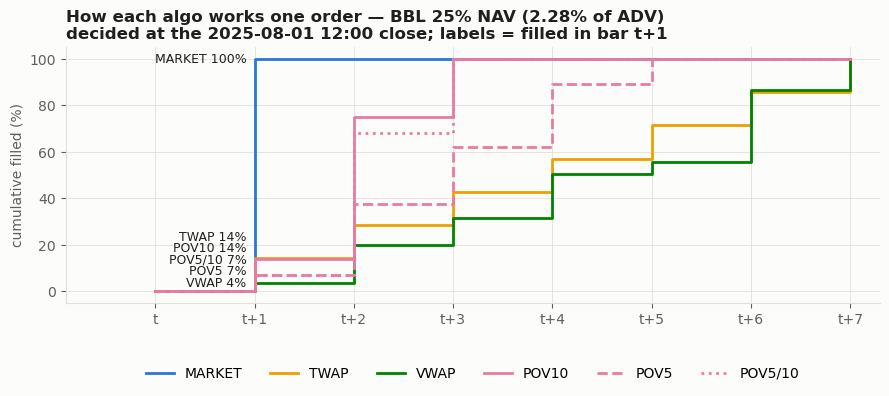

,algo,datetime,qty,bar_vwap,bar_value,participation,impact,exec_price
141452,MARKET,2025-08-01 13:00:00,167700,149.08,"34,721,300.00",0.72,0.59,149.92
141453,TWAP,2025-08-01 13:00:00,23900,149.08,"34,721,300.00",0.10,0.22,149.55
141454,TWAP,2025-08-01 15:00:00,24000,149.01,"152,479,450.00",0.02,0.11,149.36
141455,TWAP,2025-08-01 16:00:00,23900,148.76,"123,770,550.00",0.03,0.12,149.13
141456,TWAP,2025-08-01 17:00:00,24000,148.41,"134,411,550.00",0.03,0.11,148.77
141457,TWAP,2025-08-04 10:00:00,23900,149.26,"76,571,150.00",0.05,0.15,149.66
141458,TWAP,2025-08-04 11:00:00,24000,147.65,"290,258,850.00",0.01,0.08,147.97
141459,TWAP,2025-08-04 12:00:00,24000,147.93,"157,683,800.00",0.02,0.10,148.29
141460,VWAP,2025-08-01 13:00:00,6200,149.08,"34,721,300.00",0.03,0.11,149.44
141461,VWAP,2025-08-01 15:00:00,27200,149.01,"152,479,450.00",0.03,0.11,149.37


In [4]:
res, fills = ex["results"], ex["fills"]
pick = od[(od.bucket == "25% NAV") & (od.hour == 12)].sort_values("pct_adv").iloc[200]
plots.example_schedule(fills, pick); plt.show()
display(fills[fills.order_id == pick.order_id][["algo", "datetime", "qty", "bar_vwap", "bar_value", "participation", "impact", "exec_price"]])

## 5–6. Simulation engine, benchmark และ metric

* `src/engine.py` ทำงานทีละแท่ง โดยทุก algo ใช้เส้นทาง fill และ cost เดียวกัน ต่างกันแค่จำนวนที่อยากส่งในแต่ละแท่ง
* **Implementation Shortfall (IS)** เทียบกับ Q × arrival แยกเป็น timing / spread / impact / commission / opportunity
* **vs interval VWAP:** ราคา fill เฉลี่ยเทียบกับ VWAP ของตลาดช่วง t+1 … t+7
* ตัวเลขทั้งหมดเป็น bps และ `is_std` คือ std ของ IS ต่อ order ใช้เป็นตัววัดความเสี่ยง

In [5]:
cols = ["bucket", "algo", "pct_adv_mean", "is_mean", "is_ci_lo", "is_ci_hi", "is_median", "is_std",
        "timing_mean", "spread_mean", "impact_mean", "commission_mean", "opportunity_mean",
        "vs_ivwap_mean", "fully_filled_share", "bars_used_mean", "max_participation_p95"]
t = summ[cols].copy(); t["pct_adv_mean"] *= 100
display(t)

,bucket,algo,pct_adv_mean,is_mean,is_ci_lo,is_ci_hi,is_median,is_std,timing_mean,spread_mean,impact_mean,commission_mean,opportunity_mean,vs_ivwap_mean,fully_filled_share,bars_used_mean,max_participation_p95
0,1% NAV,MARKET,0.08,45.92,43.61,48.26,44.91,54.69,-0.84,23.86,6.18,16.73,0.00,32.47,1.00,1.01,0.06
1,1% NAV,TWAP,0.08,40.17,36.17,44.21,40.78,90.44,-2.82,23.82,2.42,16.72,0.03,26.71,0.99,7.00,0.03
2,1% NAV,VWAP,0.08,39.90,35.94,43.84,40.74,89.42,-2.69,23.81,2.03,16.72,0.02,26.43,0.99,7.00,0.01
3,1% NAV,POV10,0.08,45.70,43.40,48.03,44.84,54.58,-0.85,23.86,5.96,16.73,0.00,32.25,1.00,1.04,0.06
4,1% NAV,POV5,0.08,45.34,43.06,47.68,44.39,54.55,-0.86,23.85,5.62,16.73,0.00,31.89,1.00,1.09,0.05
5,1% NAV,POV5/10,0.08,45.35,43.07,47.70,44.40,54.55,-0.90,23.85,5.67,16.73,0.00,31.90,1.00,1.08,0.05
6,5% NAV,MARKET,0.38,53.58,51.24,55.93,52.34,55.93,-0.84,23.86,13.84,16.73,0.00,40.16,1.00,1.01,0.32
7,5% NAV,TWAP,0.38,43.18,39.19,47.22,43.81,90.26,-2.79,23.82,5.40,16.72,0.03,29.73,0.99,7.00,0.13
8,5% NAV,VWAP,0.38,42.44,38.49,46.40,43.34,89.18,-2.67,23.81,4.55,16.72,0.02,28.98,0.99,7.00,0.07
9,5% NAV,POV10,0.38,50.46,48.16,52.86,50.01,55.00,-0.91,23.86,10.80,16.72,0.00,37.03,1.00,1.27,0.10


## 7. ผลลัพธ์
### 7.1 ต้นทุนตามขนาด order (เส้น = ค่าเฉลี่ย, แถบสีจาง = bootstrap 95% CI)

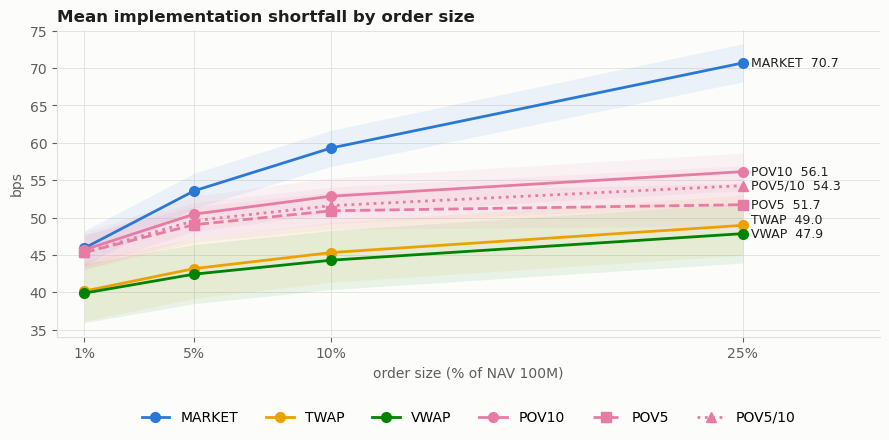

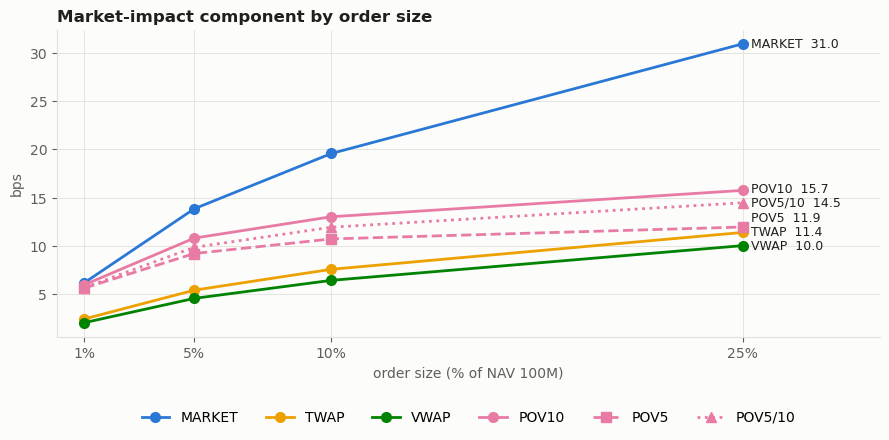

bucket,1% NAV,5% NAV,10% NAV,25% NAV
algo,,,,
MARKET,6.18,13.84,19.57,30.95
TWAP,2.42,5.40,7.56,11.39
VWAP,2.03,4.55,6.42,10.02
POV10,5.96,10.80,13.02,15.75
POV5,5.62,9.20,10.71,11.95
POV5/10,5.67,9.84,11.93,14.46


In [6]:
plots.is_by_size(summ); plt.show()
plots.is_by_size(summ, col="impact_mean", title="Market-impact component by order size", ci=False); plt.show()
display(summ.pivot(index="algo", columns="bucket", values="impact_mean")[sorted(summ.bucket.unique(), key=lambda b: float(b.split("%")[0]))])

### 7.2 Cost–risk frontier
ยิ่งต่ำยิ่งถูก ยิ่งไปซ้ายยิ่งเสี่ยงน้อย

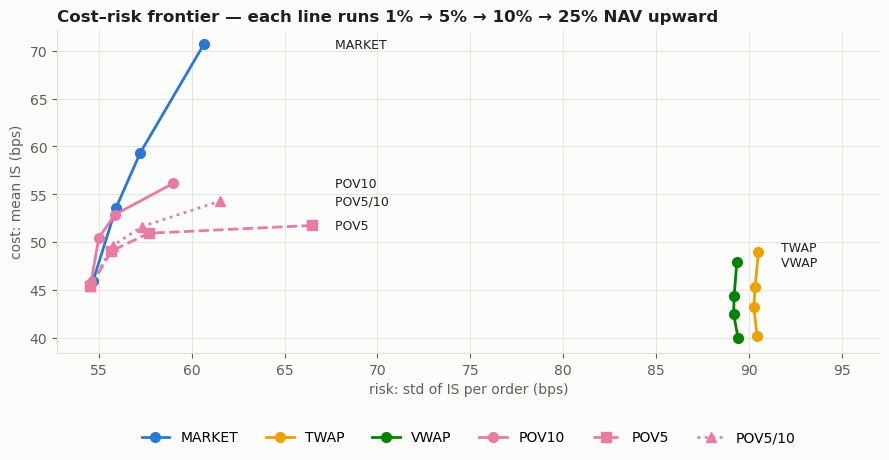

bucket,1% NAV,5% NAV,10% NAV,25% NAV
algo,,,,
MARKET,54.69,55.93,57.23,60.66
TWAP,90.44,90.26,90.33,90.51
VWAP,89.42,89.18,89.20,89.35
POV10,54.58,55.00,55.87,59.02
POV5,54.55,55.68,57.69,66.47
POV5/10,54.55,55.75,57.31,61.52


In [7]:
plots.frontier(summ); plt.show()
display(summ.pivot(index="algo", columns="bucket", values="is_std")[sorted(summ.bucket.unique(), key=lambda b: float(b.split("%")[0]))])

### 7.3 แยกตามชั่วโมงที่ตัดสินใจ และระดับ volatility (order 25% NAV)

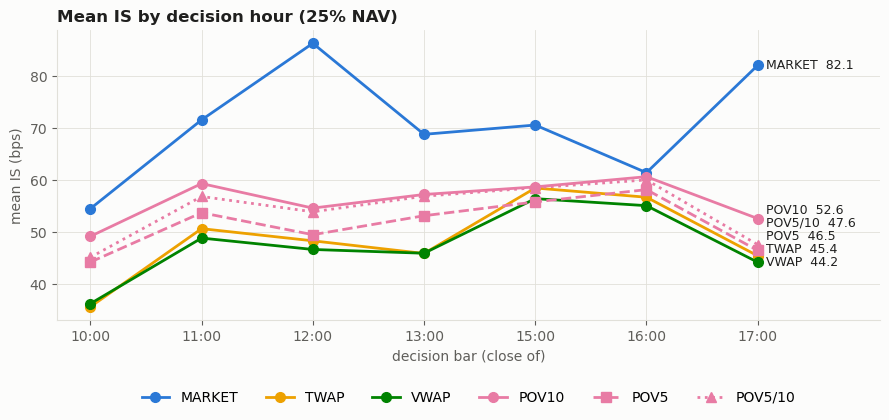

algo,MARKET,TWAP,VWAP,POV10,POV5,POV5/10
hour,,,,,,
10,54.53,35.62,36.22,49.20,44.24,45.16
11,71.64,50.67,48.86,59.36,53.75,56.87
12,86.39,48.34,46.67,54.64,49.51,53.92
13,68.85,45.90,45.94,57.26,53.17,56.92
15,70.64,58.51,56.46,58.72,55.83,58.56
16,61.46,56.73,55.11,60.69,58.20,60.07
17,82.14,45.45,44.21,52.62,46.48,47.60


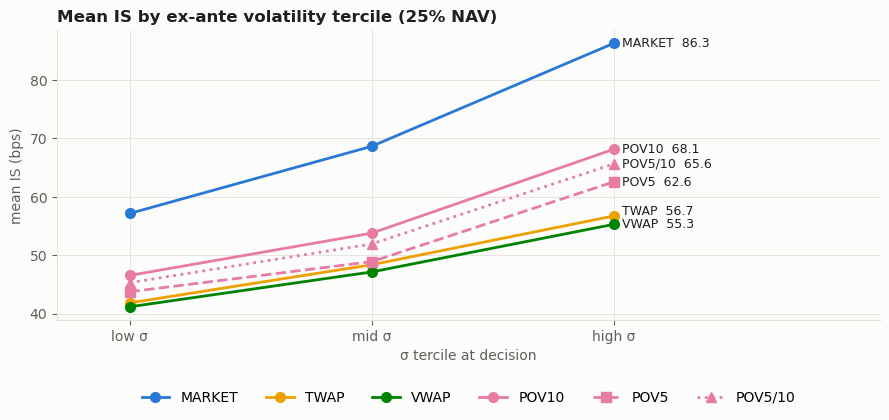

algo                 MARKET  TWAP  VWAP  POV10  POV5  POV5/10
bucket  vol_tercile                                          
1% NAV  low σ         38.14 35.29 35.15  37.96 37.70    37.70
        mid σ         45.25 39.97 39.54  44.90 44.44    44.47
        high σ        54.39 45.26 45.00  54.24 53.89    53.89
5% NAV  low σ         44.01 37.54 37.06  41.96 40.96    41.31
        mid σ         52.48 42.84 41.95  49.05 47.82    48.45
        high σ        64.25 49.15 48.30  60.38 58.37    58.99
10% NAV low σ         48.41 39.15 38.45  43.87 42.66    42.86
        mid σ         57.90 44.90 43.73  51.35 49.29    50.36
        high σ        71.64 51.93 50.73  63.38 60.80    61.59
25% NAV low σ         57.14 41.82 41.15  46.53 43.73    45.29
        mid σ         68.65 48.36 47.12  53.77 48.89    51.91
        high σ        86.30 56.72 55.28  68.14 62.56    65.63

In [8]:
bh, bv = ex["by_hour"], ex["by_vol"]
plots.by_group(bh, "hour", "25% NAV", "Mean IS by decision hour (25% NAV)", "decision bar (close of)"); plt.show()
display(bh[bh.bucket == "25% NAV"].set_index("hour").drop(columns="bucket"))
plots.by_group(bv, "vol_tercile", "25% NAV", "Mean IS by ex-ante volatility tercile (25% NAV)", "σ tercile at decision"); plt.show()
display(bv.set_index(["bucket", "vol_tercile"]))

### 7.4 เทียบ POV ทั้ง 3 แบบ
rate ต่ำลง impact น้อยลง แต่ทำไม่เสร็จบ่อยขึ้น

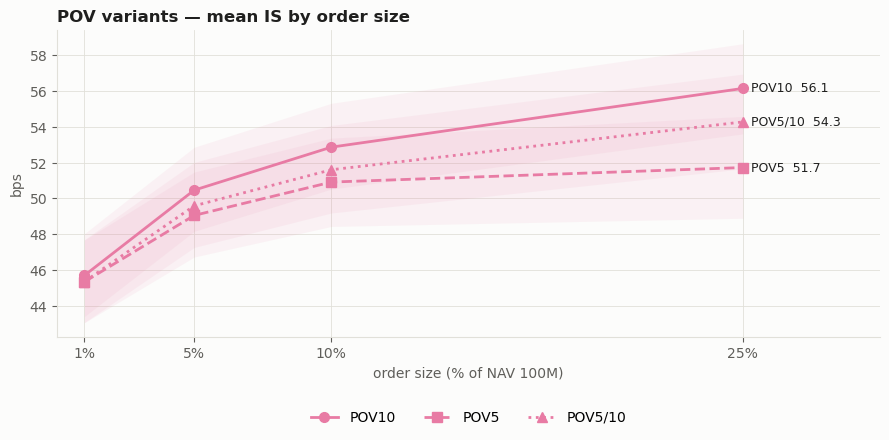

is_mean  is_std  impact_mean  timing_mean  opportunity_mean  fully_filled_share  bars_used_mean
bucket  algo                                                                                                    
1% NAV  POV10      45.70   54.58         5.96        -0.85              0.00                1.00            1.04
        POV5       45.34   54.55         5.62        -0.86              0.00                1.00            1.09
        POV5/10    45.35   54.55         5.67        -0.90              0.00                1.00            1.08
5% NAV  POV10      50.46   55.00        10.80        -0.91              0.00                1.00            1.27
        POV5       49.05   55.68         9.20        -0.73              0.00                1.00            1.52
        POV5/10    49.59   55.75         9.84        -0.84              0.00                1.00            1.40
10% NAV POV10      52.87   55.87        13.02        -0.73              0.00                1.00            1.52
        POV5       50.92   57.69        10.71        -0.37             -0.00                1.00            2.06
        POV5/10    51.60   57.31        11.93        -0.91              0.00                1.00            1.75
25% NAV POV10      56.15   59.02        15.75        -0.17              0.02                0.99            2.33
        POV5       51.73   66.47        11.95        -0.19             -0.06                0.94            3.68
        POV5/10    54.28   61.52        14.46        -0.64              0.01                0.98            2.86

In [9]:
pov = list(C.POV_SCHEDULES)
plots.is_by_size(summ, algos=pov, title="POV variants — mean IS by order size"); plt.show()
display(summ[summ.algo.isin(pov)].set_index(["bucket", "algo"])[["is_mean", "is_std", "impact_mean", "timing_mean",
        "opportunity_mean", "fully_filled_share", "bars_used_mean"]])

## 8. การทดสอบทางสถิติ (paired บน order_id)

`mean_diff` = IS ของ a − IS ของ b (ค่าติดลบ = a ถูกกว่า) มี bootstrap 95% CI ประกอบ
* `t_p_holm` คือ paired t-test ที่ปรับด้วย Holm (15 คู่ต่อ bucket)
* `wilcoxon_p` คือ signed-rank test
* `share_a_cheaper` คือสัดส่วนของ order ที่ a ถูกกว่า b

In [10]:
display(ex["paired"])

,bucket,a,b,n,mean_diff,ci_lo,ci_hi,share_a_cheaper,t_p,wilcoxon_p,t_p_holm,significant
0,1% NAV,MARKET,TWAP,2000,5.75,2.61,8.82,0.45,0.00,0.00,0.00,True
1,1% NAV,MARKET,VWAP,2000,6.03,2.93,9.05,0.45,0.00,0.00,0.00,True
2,1% NAV,MARKET,POV10,2000,0.23,0.11,0.36,0.01,0.00,0.00,0.00,True
3,1% NAV,MARKET,POV5,2000,0.58,0.37,0.83,0.02,0.00,0.00,0.00,True
4,1% NAV,MARKET,POV5/10,2000,0.57,0.35,0.81,0.02,0.00,0.00,0.00,True
5,1% NAV,TWAP,VWAP,2000,0.27,-0.16,0.69,0.47,0.19,0.05,0.39,False
6,1% NAV,TWAP,POV10,2000,-5.53,-8.62,-2.41,0.54,0.00,0.00,0.00,True
7,1% NAV,TWAP,POV5,2000,-5.17,-8.25,-2.03,0.54,0.00,0.00,0.00,True
8,1% NAV,TWAP,POV5/10,2000,-5.18,-8.26,-2.03,0.54,0.00,0.00,0.00,True
9,1% NAV,VWAP,POV10,2000,-5.80,-8.82,-2.71,0.54,0.00,0.00,0.00,True


## 9. Sensitivity และ robustness
ปรับทีละพารามิเตอร์ ตัวอื่นคงไว้ที่ค่าหลัก แล้วรันซ้ำบน order 8,000 ตัวเดิม

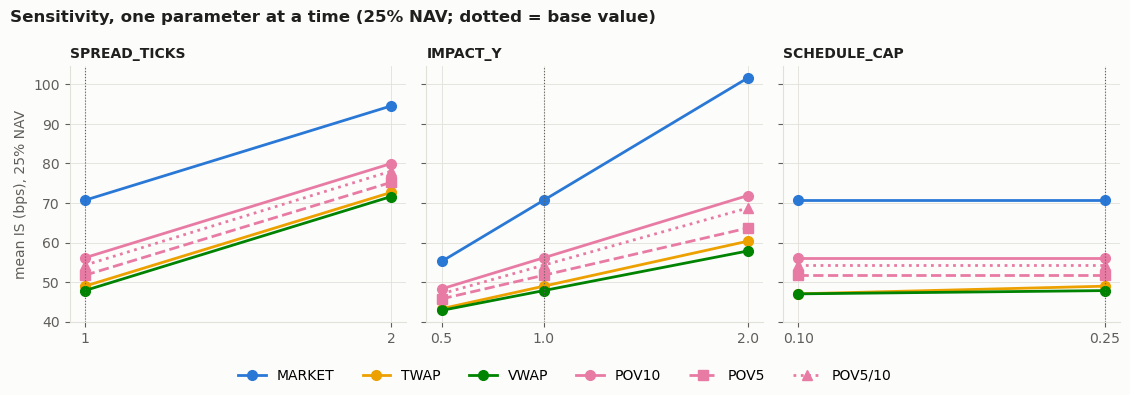

bucket             1% NAV 5% NAV 10% NAV 25% NAV
param        value                              
IMPACT_Y     0.50    VWAP   VWAP    VWAP    VWAP
             1.00    VWAP   VWAP    VWAP    VWAP
             2.00    VWAP   VWAP    VWAP    VWAP
SCHEDULE_CAP 0.10    VWAP   VWAP    VWAP    VWAP
             0.25    VWAP   VWAP    VWAP    VWAP
SPREAD_TICKS 1.00    VWAP   VWAP    VWAP    VWAP
             2.00    VWAP   VWAP    VWAP    VWAP

In [11]:
sens = ex["sensitivity"]
plots.sensitivity(sens, "25% NAV"); plt.show()
win = sens[sens["rank"] == 1].pivot_table(index=["param", "value"], columns="bucket", values="algo", aggfunc="first")
display(win[sorted(win.columns, key=lambda b: float(b.split("%")[0]))])

**ผลรายปี:** ถ้าข้อสรุปเป็นจริงทุกปี แปลว่าไม่ได้มาจากสภาพตลาดช่วงใดช่วงหนึ่ง

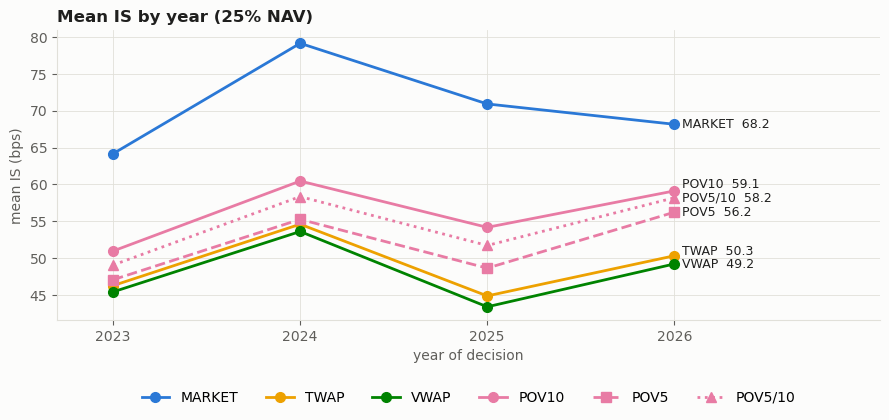

algo          MARKET  TWAP  VWAP  POV10  POV5  POV5/10
bucket  year                                          
1% NAV  2023   41.33 37.71 37.79  41.23 40.94    40.97
        2024   51.58 45.55 45.16  50.93 50.36    50.39
        2025   42.36 34.86 34.28  42.24 41.87    41.86
        2026   48.55 42.82 42.64  48.52 48.34    48.35
5% NAV  2023   48.39 40.55 40.17  45.63 44.42    44.84
        2024   60.11 48.80 47.93  55.52 53.80    54.52
        2025   51.19 38.30 37.19  47.74 46.15    46.65
        2026   54.61 45.25 44.68  53.05 51.95    52.44
10% NAV 2023   53.68 42.63 41.93  47.97 46.20    46.73
        2024   66.49 51.03 49.96  57.58 55.70    56.40
        2025   57.80 40.77 39.31  50.58 47.98    48.70
        2026   59.15 47.02 46.20  55.41 53.90    54.71
25% NAV 2023   64.17 46.25 45.40  50.95 47.05    49.05
        2024   79.16 54.59 53.60  60.45 55.24    58.34
        2025   70.92 44.85 43.37  54.16 48.62    51.70
        2026   68.16 50.30 49.19  59.11 56.21    58.17

In [12]:
by = ex["by_year"]
plots.by_group(by, "year", "25% NAV", "Mean IS by year (25% NAV)", "year of decision"); plt.show()
display(by.set_index(["bucket", "year"]))

## 10. สรุปและข้อจำกัด

ตัวเลขทั้งหมดมาจากการรันด้วย seed ใน `constants.py` (8,000 order, ก.พ. 2023 → พ.ย. 2026, หุ้น 10 ตัวที่ lock) รันซ้ำได้ผลเดิมทุกครั้ง

### ข้อค้นพบ
1. **มีต้นทุนพื้นฐานราว 40 bps ที่ algo ไหนก็เลี่ยงไม่ได้** มาจาก ½ spread (≈ 24 bps ภายใต้ค่าสมมติ 1 tick) กับ commission + VAT (≈ 17 bps) algo ต่างกันแค่ส่วน impact กับ timing

2. **H1 ยืนยัน:** order ยิ่งใหญ่ MARKET ยิ่งแพงกว่าตัวอื่น
   * MARKET แพงกว่า VWAP 6.0 bps ที่ 1% NAV (≈ 0.08% ของ ADV) และ **22.8 bps** ที่ 25% NAV (≈ 1.9% ของ ADV, 95% CI 19.6–26.0) หรือประมาณ 57,000 บาทต่อ order ขนาด 25M
   * ที่ 1% NAV ความต่างมีนัยสำคัญทางสถิติ แต่ในจำนวน 6 bps นั้น มีเพียงราว 4 bps ที่มาจาก impact จริง อีกราว 2 bps มาจาก timing ซึ่งสำหรับ order ที่สุ่มฝั่งซื้อขาย ค่าเฉลี่ยควรเป็นศูนย์ จึงน่าจะเป็นความบังเอิญของตัวอย่าง ควรตีความว่าที่ขนาดนี้ algo ต่างกันน้อยมาก

3. **H2 ยืนยัน แต่ส่วนต่างเล็ก:** VWAP ถูกกว่า TWAP 0.7–1.1 bps อย่างมีนัยสำคัญตั้งแต่ 5% NAV ขึ้นไป (ที่ 1% NAV ไม่มีนัยสำคัญ) ส่วนต่างมาจาก impact ทั้งหมด

4. **H3 ยืนยัน:** ต้นทุนที่ต่ำลงแลกมาด้วยความเสี่ยงที่สูงขึ้น std ของ IS ต่อ order:
   * TWAP/VWAP ≈ 89–90 bps
   * MARKET 55–61 bps
   * POV ทั้ง 3 แบบ 55–66 bps
   * POV แพงกว่า VWAP ราว 4–9 bps แต่ผลแกว่งน้อยกว่ามาก

5. **H4 ยืนยันครึ่งเดียว:**
   * **rate ต่ำกว่าถูกกว่าจริง:** ที่ 25% NAV ต้นทุนเรียงเป็น POV5 51.7 < POV5/10 54.3 < POV10 56.2 bps แต่ POV5 ทำเสร็จครบเพียง 94% ของ order (POV10 99%) และ std สูงขึ้นเป็น 66 bps
   * **การแบ่ง rate ตามช่วงเวลาไม่ช่วย:** POV5/10 ไม่ชนะ POV5 ในทุกขนาด (แพงกว่า 0.5–2.6 bps อย่างมีนัยสำคัญตั้งแต่ 5% NAV) เพราะแท่งช่วงบ่าย 15–17 มีมูลค่าซื้อขายราวครึ่งวัน การเพิ่ม rate เป็น 10% ตรงนั้นจึงเพิ่ม impact โดยไม่ได้ลดความเสี่ยงอย่างมีนัย

6. **Volume profile เปลี่ยนไปตามเวลาจริง:** เฉลี่ย 3 เดือนแรก (ต้นปี 2023) เทียบกับ 3 เดือนล่าสุด (ปลายปี 2026): แท่ง 17:00 ลดจาก 24% เหลือ 18% ส่วนแท่ง 11:00 เพิ่มจาก 27% เป็น 33% การใช้ profile แบบ rolling 21 วันจึงมีความหมาย เพราะ profile คงที่จะส่งผิดจังหวะมากขึ้นเรื่อยๆ

7. **ช่วงเวลาของวัน (25% NAV):**
   * MARKET ที่ตัดสินใจตอนปิดแท่ง 12:00 หรือ 17:00 แพงถึง ≈ 82–86 bps เพราะแท่งถัดไปบาง (แท่ง 13:00 ก่อนพักเที่ยง และ auction เช้าวันถัดไป)
   * TWAP/VWAP ถูกที่สุดเมื่อตัดสินใจตอน 10:00 (≈ 36 bps) ซึ่ง window อยู่ในวันเดียวทั้งหมด และแพงขึ้นเมื่อ window คร่อมข้ามคืน (ตัดสินใจ 15:00–16:00 ≈ 55–58 bps)
   * มี order ราว 285 ตัวต่อชั่วโมง ความต่างระดับไม่กี่ bps ระหว่างชั่วโมงจึงยังไม่แน่นอนทางสถิติ

8. **Volatility:** σ ยิ่งสูง ทุก algo ยิ่งแพง MARKET ไวต่อ σ ที่สุด (25% NAV: 57 → 86 bps เทียบกับ VWAP 41 → 55) อันดับไม่เปลี่ยน

9. **Robustness:**
   * VWAP เป็นอันดับ 1 ในทุกค่าของ sensitivity (spread, impact Y, cap) และทุกขนาด order
   * spread 2 tick เพิ่มต้นทุนให้ทุก algo ราว 24 bps เท่าๆ กัน ส่วน impact Y = 2 ทำให้ MARKET แพงขึ้นมาก (25% NAV ≈ 102 bps เทียบกับ VWAP ≈ 58)
   * **รายปี:** VWAP ถูกที่สุดทุกปีในทุกขนาดตั้งแต่ 5% NAV ขึ้นไป (ที่ 1% NAV ปี 2023 TWAP ต่ำกว่า VWAP เพียง 0.08 bps) ปี 2024 เป็นปีที่ทุก algo แพงที่สุด

### ข้อเสนอเชิงปฏิบัติ (ภายใต้สมมติฐานของแบบจำลองนี้)
* **ค่าเริ่มต้น:** ใช้ **VWAP กับ profile แบบ rolling** ถ้ารับความไม่แน่นอนของราคาตลอดวันได้
* **ต้องการความแน่นอนของราคา:** ใช้ **POV5** ถูกกว่า POV10 และ POV5/10 และแกว่งใกล้ MARKET แต่สำหรับ order ราว 2% ของ ADV ขึ้นไป ต้องยอมรับว่าอาจทำไม่เสร็จภายในวัน
* **ไม่แนะนำ POV5/10:** ในข้อมูลนี้ไม่มีข้อดีเหนือ POV5
* **หลีกเลี่ยง MARKET order ก้อนใหญ่** ก่อนพักเที่ยงและหลังปิดตลาด

### ข้อจำกัด
* **ไม่มี bid/ask และไม่มี order book:** spread เป็นค่าสมมติ ซึ่งกำหนดระดับต้นทุนส่วนใหญ่ (แต่ไม่เปลี่ยนอันดับของ algo)
* **แท่งรายชั่วโมง:** สมมติว่า child ได้ราคาเท่า VWAP ของแท่งพอดี ส่วน MARKET ก็สมมติให้ fill ที่ VWAP ของแท่ง t+1
* **Impact model ไม่ได้ calibrate จาก order จริงของเรา:** ใช้ square-root law แบบชั่วคราว ไม่มี permanent impact และไม่มีการรั่วไหลของข้อมูล
* **Look-ahead เล็กน้อย 2 จุด:**
  * cap และ POV ใช้มูลค่าซื้อขายของแท่งที่กำลัง fill
  * หุ้น 10 ตัวที่ lock เลือกโดยรู้สภาพคล่องตลอดช่วง (ชุด B) แต่เพราะงานนี้วัดต้นทุน execution ไม่ใช่ผลตอบแทน ผลกระทบจึงเล็ก
* **ขอบเขตการทดลอง:** ฝั่งขายสมมติว่ามีหุ้นอยู่แล้ว, horizon เดียว (1 วัน) และเฉพาะหุ้นสภาพคล่องสูง ผลกับหุ้นที่คล่องตัวน้อยอาจต่างออกไป